<a href="https://colab.research.google.com/github/Sylvieia/Machine-learning/blob/main/Siec%20neuronowa%20na%20zbiorze%20z%20glejakiem%20m%C3%B3zgu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasyfikacja binarna z użyciem sieci neuronowych na zbiorze **Glioma Grading Clinical and Mutation Features**

---

Zbiór dotyczy chorych na raka mózgu. Ma 839 pacjentów i 23 cechy, w tym wiek, płeć, rasę oraz informacje o mutacjach 20 genów. Celem jest klasyfikacja binarna: LGG = 0 (glejak niższego stopnia) oraz GBM = 1 (glioblastoma).

## 1. Przeprowadź wstępną analizę danych (exploratory data analysis, EDA).

Pobranie i podgląd danych:

In [2]:

 !pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=759)

X = data.data.features
y = data.data.targets

print(X.head())
print(y.head())
print(X.shape)
print(data.metadata)
print(data.variables)

   Gender  Age_at_diagnosis   Race  IDH1  TP53  ATRX  PTEN  EGFR  CIC  MUC16  \
0       0             51.30  white     1     0     0     0     0    0      0   
1       0             38.72  white     1     0     0     0     0    1      0   
2       0             35.17  white     1     1     1     0     0    0      0   
3       1             32.78  white     1     1     1     0     0    0      1   
4       0             31.51  white     1     1     1     0     0    0      0   

   ...  FUBP1  RB1  NOTCH1  BCOR  CSMD3  SMARCA4  GRIN2A  IDH2  FAT4  PDGFRA  
0  ...      1    0       0     0      0        0       0     0     0       0  
1  ...      0    0       0     0      0        0       0     0     0       0  
2  ...      0    0       0     0      0        0       0     0     0       0  
3  ...      0    0       0     0      0        0       0     0     1       0  
4  ...      0    0       0     0      0        0       0     0     0       0  

[5 rows x 23 columns]
   Grade
0      0
1   

Prawie wszystkie zmienne sa binarne, oprocz Race, czyli rasy człowieka -> zamiana pozniej na one hot encoding. Nie ma braków danych.

In [4]:
import pandas as pd
import numpy as np

df = pd.concat([X, y], axis=1)

print("\n=== Podsumowanie statystyczne ===")
display(df.describe(include='all'))

print("\n=== Rozkład zmiennej docelowej (Grade) ===")
print(df['Grade'].value_counts(normalize=True))


=== Podsumowanie statystyczne ===


,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,...,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
count,839.000000,839.000000,839,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,...,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000
unique,NaN,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,white,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,765,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.418355,50.935411,NaN,0.481526,0.414779,0.258641,0.168057,0.133492,0.132300,0.116806,...,0.047676,0.045292,0.034565,0.032181,0.032181,0.032181,0.027414,0.027414,0.026222,0.419547
std,0.493583,15.702339,NaN,0.499957,0.492978,0.438149,0.374140,0.340309,0.339019,0.321380,...,0.213206,0.208068,0.182784,0.176586,0.176586,0.176586,0.163383,0.163383,0.159889,0.493779
min,0.000000,14.420000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,38.055000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,51.550000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,62.800000,NaN,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000



=== Rozkład zmiennej docelowej (Grade) ===
Grade
0    0.580453
1    0.419547
Name: proportion, dtype: float64


## 2. Przeprowadź preprocessing danych (normalizacja, one-hot encoding dla zmiennych kategorycznych) i 3. Podziel dane na zbiór treningowy i zbiór testowy (np. w proporcjach 80/20).
W tym punkcie potrzebna jest zamiana kodowania tylko jednej zmiennej kategorycznej `Race` i normalizacja wieku

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_encoded = pd.get_dummies(X, columns=['Race'], drop_first=True)

# Przekształcenie wartości logicznych (True/False) po get_dummies na liczbowe (1/0)
for col in X_encoded.columns:
    if X_encoded[col].dtype == 'bool':
        X_encoded[col] = X_encoded[col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y.values.ravel(),
    test_size=0.2,
    random_state=42,
    stratify=y.values.ravel()
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Kształt zbioru treningowego:", X_train_scaled.shape)
print("Kształt zbioru testowego:", X_test_scaled.shape)
print("Przykładowy wiersz po preprocesingu i standaryzacji wszystkich kolumn:\n", X_train_scaled[0])

Kształt zbioru treningowego: (671, 25)
Kształt zbioru testowego: (168, 25)
Przykładowy wiersz po preprocesingu i standaryzacji wszystkich kolumn:
 [-0.8282087  -1.19895182  1.04108162  1.21868174 -0.58710253 -0.45000996
 -0.36267695 -0.39861591 -0.35206974 -0.30468652 -0.30175638 -0.24841268
 -0.25840405 -0.22742941 -0.22742941 -0.18411492 -0.18839806 -0.18839806
 -0.17070766 -0.17974341 -0.16602736 -0.16602736 -0.14055902 -0.2712932
  0.31336827]


## 4. Zbuduj model w Keras lub PyTorch z jedną lub dwiema warstwami ukrytymi & 5. Wytrenuj model, używając funkcji straty binary cross-entropy


Wybrano biblioteke Keras, ponieważ jest mała liczba próbek. Korzystanie z Keras umożliwia szybkie i proste stworzenie sieci, przy wybranym nieskomplikowanym zbiorem danych.

In [11]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

tf.random.set_seed(42)
np.random.seed(42)

model = Sequential([ # po kolei warstwami idzie
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),  # wylacza 30% neuronow przy uczeniu - reg overfitting

    Dense(32, activation='relu'), #klasyczna, przepuszcza dodatnie jak dodatnie, ujemne jak zero. Pozwala na nieliniowosc - nowe
    Dropout(0.2), # wylacza 20% neuronow

    # Warstwa wyjściowa z 1 neuronem i z funkcją sigmoid
    Dense(1, activation='sigmoid') # (klasyfikacja binarna: LGG 0 / GBM 1)
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Konfiguracja EarlyStopping (zatrzyma trening, gdy strata na zbiorze walidacyjnym przestanie maleć)
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True # propagacja wsteczna
)

history = model.fit(
    X_train_scaled, y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.2,  # Wydzielenie części danych treningowych do walidacji
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6455 - loss: 0.6726 - val_accuracy: 0.7556 - val_loss: 0.6006
Epoch 2/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7743 - loss: 0.5376 - val_accuracy: 0.8148 - val_loss: 0.5149
Epoch 3/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8060 - loss: 0.4855 - val_accuracy: 0.8370 - val_loss: 0.4611
Epoch 4/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8321 - loss: 0.4288 - val_accuracy: 0.8370 - val_loss: 0.4246
Epoch 5/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8470 - loss: 0.4012 - val_accuracy: 0.8444 - val_loss: 0.3969
Epoch 6/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8526 - loss: 0.3815 - val_accuracy: 0.8444 - val_loss: 0.3813
Epoch 7/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8638 - loss: 0.3609 - val_accuracy: 0.8444 - val_loss: 0.3705
Epoch 8/80
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8713 - loss: 0.3626 - val_accuracy: 0.8444 - val_loss

## 6. Oceń model na zbiorze testowym, obliczając metryki takie jak accuracy, precision, recall (confidency matrix) i F1-score.


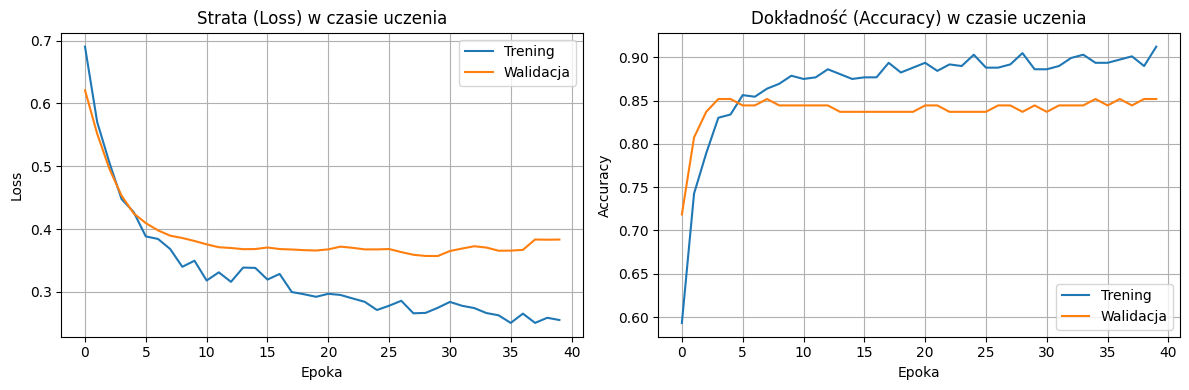

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
=== Raport Klasyfikacji (Zbiór Testowy) ===
              precision    recall  f1-score   support

     LGG (0)       0.90      0.83      0.86        98
     GBM (1)       0.78      0.87      0.82        70

    accuracy                           0.85       168
   macro avg       0.84      0.85      0.84       168
weighted avg       0.85      0.85      0.85       168



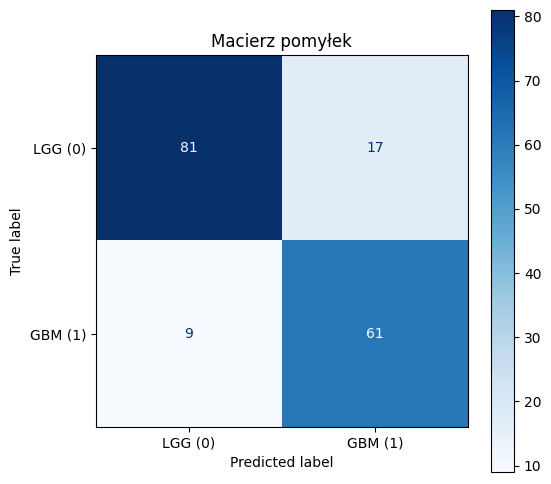

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Trening')
plt.plot(history.history['val_loss'], label='Walidacja')
plt.title('Strata (Loss) w czasie uczenia')
plt.xlabel('Epoka')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Trening')
plt.plot(history.history['val_accuracy'], label='Walidacja')
plt.title('Dokładność (Accuracy) w czasie uczenia')
plt.xlabel('Epoka')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print("=== Raport Klasyfikacji (Zbiór Testowy) ===")
print(classification_report(y_test, y_pred, target_names=['LGG (0)', 'GBM (1)']))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['LGG (0)', 'GBM (1)'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Macierz pomyłek')
plt.show()

Z wykresów wynika, że model wraz z kolenymi epokami coraz lepiej sie dopasowuje do danych treningowych, ale jego wyniki precyzji wskazują na przeuczenie. Podejrzewam, że wynika to z dość niewielkiej próbki jak na sieć neuronową.

- 81 przypadków LGG model rozpoznał poprawnie jako LGG.
- 17 przypadków LGG błędnie oznaczył jako GBM.
- 9 przypadków GBM błędnie oznaczył jako LGG.
- 61 przypadków GBM poprawnie rozpoznał jako GBM.

## 7. Zoptymalizuj hiperparametry modelu, aby uzyskać jak najlepszą metrykę.

In [9]:
!pip install keras-tuner -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 8.5 MB/s eta 0:00:00


In [12]:
import keras_tuner as kt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report

def build_model(hp):
    model = Sequential()

    # Definiujemy wejście modelu przy użyciu klasy Input
    model.add(Input(shape=(X_train_scaled.shape[1],)))

    # szukanie liczby neuronow w 1 warstwie, 2^n neuronow bo komp wtedy najlepiej liczy
    hp_units_1 = hp.Int('units_1', min_value=16, max_value=128, step=16)
    model.add(Dense(units=hp_units_1, activation='relu'))

    # szukanie współczynnika dropout po 1. warstwie
    hp_dropout_1 = hp.Float('dropout_1', min_value=0.1, max_value=0.5, step=0.1)
    model.add(Dropout(rate=hp_dropout_1))

    # Optymalizacja liczby neuronów w 2. warstwie
    hp_units_2 = hp.Int('units_2', min_value=16, max_value=64, step=16)
    model.add(Dense(units=hp_units_2, activation='relu'))

    # Optymalizacja współczynnika Dropout po 2. warstwie
    hp_dropout_2 = hp.Float('dropout_2', min_value=0.1, max_value=0.5, step=0.1)
    model.add(Dropout(rate=hp_dropout_2))

    model.add(Dense(1, activation='sigmoid'))

    # szukanie learning rate - jak szybko trwa uczenie, jakie kroki stawia
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Uruchomienie tunera RandomSearch
tuner = kt.RandomSearch( # Losuje on różne kombinacje hiperparametrów,
                         # np. liczbę neuronów, dropout, learning rate
    build_model,
    objective='val_accuracy', # wg dokladnosci
    max_trials=10, # kombinacje
    executions_per_trial=1, # kombinacja raz uruchamiana
    directory='glioma_tuning', # tutaj zapisuje wyniki wyszukiwania
    project_name='hyperparameter_tuning',
    overwrite=True
)

# Zdefiniowanie wcześniejszego zatrzymania w procesie wyszukiwania
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# patience - jeśli przez 10 kolejnych epok val_loss się nie poprawi, zatrzymaj trening.

print("=== Rozpoczęcie przeszukiwania hiperparametrów ===")
tuner.search(
    X_train_scaled, y_train,
    epochs=50, # max 50 iteracji przez zbior
    validation_split=0.2, # odkładane na walidację,
    callbacks=[early_stopping],
    verbose=1 # w konsoli wyniki
)

# Pobranie najlepszych hiperparametrów
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\n=== Najlepsze znalezione hiperparametry ===")
print(f"- Liczba neuronów w 1. warstwie: {best_hps.get('units_1')}")
print(f"- Dropout w 1. warstwie: {best_hps.get('dropout_1'):.2f}")
print(f"- Liczba neuronów w 2. warstwie: {best_hps.get('units_2')}")
print(f"- Dropout w 2. warstwie: {best_hps.get('dropout_2'):.2f}")
print(f"- Współczynnik uczenia (Learning rate): {best_hps.get('learning_rate')}")

Trial 10 Complete [00h 00m 12s]
val_accuracy: 0.8222222328186035

Best val_accuracy So Far: 0.8740741014480591
Total elapsed time: 00h 01m 36s

=== Najlepsze znalezione hiperparametry ===
- Liczba neuronów w 1. warstwie: 80
- Dropout w 1. warstwie: 0.30
- Liczba neuronów w 2. warstwie: 16
- Dropout w 2. warstwie: 0.20
- Współczynnik uczenia (Learning rate): 0.0001


In [13]:
# Budowa i finalne trenowanie najlepszego modelu na pełnym zbiorze treningowym
best_model = tuner.hypermodel.build(best_hps)

# Zwiększamy liczbę epok i patience dla pełniejszego treningu
final_early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history_tuned = best_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[final_early_stopping],
    verbose=1
)

# Ocena na zbiorze testowym
y_pred_tuned_prob = best_model.predict(X_test_scaled)
y_pred_tuned = (y_pred_tuned_prob > 0.5).astype(int).ravel()

print("\n=== Raport Klasyfikacji po Optymalizacji Hiperparametrów ===")
print(classification_report(y_test, y_pred_tuned, target_names=['LGG (0)', 'GBM (1)']))

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5280 - loss: 0.7468 - val_accuracy: 0.4519 - val_loss: 0.7742
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5317 - loss: 0.7411 - val_accuracy: 0.5111 - val_loss: 0.7499
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5951 - loss: 0.6839 - val_accuracy: 0.5407 - val_loss: 0.7279
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6082 - loss: 0.6751 - val_accuracy: 0.5704 - val_loss: 0.7081
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5709 - loss: 0.6812 - val_accuracy: 0.5926 - val_loss: 0.6899
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6493 - loss: 0.6482 - val_accuracy: 0.6000 - val_loss: 0.6729
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6623 - loss: 0.6429 - val_accuracy: 0.6148 - val_loss: 0.6570
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6698 - loss: 0.6201 - val_accuracy: 0.6222 - 

Ostateczny model ma dobre wyniki - 88% śrendiej dokładności. Ma wysoki recall,  co oznacza, że model jest trochę bardziej „czuły” na "1" - pacject z glejakiem niż na LGG - pacjent z glejakiem nizszego stopnia. Model rzadziej przeocza pacjentów ze złośliwym rakiem, ale kosztem większej liczby fałszywych alarmów. Takie zachowanie modelu jest pożądane dla danych medycznych. F1 = 89% wskazuje na dobry balans między dokładnością a precyzją.

## 8. Porównaj z innymi modelami jak np. las losowy czy SVC.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# 1. Las Losowy (Random Forest)
print("=== Trenowanie i ewaluacja Lasu Losowego ===")
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

print(classification_report(y_test, y_pred_rf, target_names=['LGG (0)', 'GBM (1)'])
)

# 2. Support Vector Classifier (SVC)
print("=== Trenowanie i ewaluacja SVC ===")
svc_model = SVC(random_state=42, kernel='rbf', probability=True)
svc_model.fit(X_train_scaled, y_train)
y_pred_svc = svc_model.predict(X_test_scaled)

print(classification_report(y_test, y_pred_svc, target_names=['LGG (0)', 'GBM (1)']))

=== Trenowanie i ewaluacja Lasu Losowego ===
              precision    recall  f1-score   support

     LGG (0)       0.82      0.83      0.82        98
     GBM (1)       0.75      0.74      0.75        70

    accuracy                           0.79       168
   macro avg       0.79      0.78      0.79       168
weighted avg       0.79      0.79      0.79       168

=== Trenowanie i ewaluacja SVC ===
              precision    recall  f1-score   support

     LGG (0)       0.91      0.85      0.88        98
     GBM (1)       0.81      0.89      0.84        70

    accuracy                           0.86       168
   macro avg       0.86      0.87      0.86       168
weighted avg       0.87      0.86      0.86       168



Najsłabiej wypadły lasy losowe, lecz mają dobre wyniki - ok 80%.

SVC wyodrebniło prawie tak dobrze klasy 0 i 1 jak sieci. Średnia prezycja to 86 %, Recall klasy 1 to 89%. Model dość dobrze wyłapuje GBM, ale dokładność 81% oznacza, że część przypadków oznaczonych jako GBM to w rzeczywistości LGG - klasa 0 - glejak nizszego stopnia.

## Podsumowanie i porównanie wszystkich wyników


| Model | Dokładność (Accuracy) | F1-Score (LGG - 0) | F1-Score (GBM - 1) | Precyzja (GBM - 1) | Czułość/Recall (GBM - 1) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Sieć Neuronowa (Bazowa)** | 0.85 | 0.87 | 0.83 | 0.79 | 0.87 |
| **Sieć Neuronowa (Po tuningu)** | **0.86** | 0.87 | **0.84** | 0.79 | **0.90** |
| **Las Losowy (Random Forest)** | 0.79 | 0.82 | 0.75 | 0.75 | 0.74 |
| **Klasyfikator SVC (RBF)** | **0.86** | **0.88** | **0.84** | **0.81** | 0.89 |


1. Najwyższą dokładność - 86% oraz najlepsze zbalansowane wyniki F1-score osiągnęła siec neuronowa po optymalizacji z uzyciem biblioteki Keras. Niewiele słabiej wypadł klasyczny klasyfikator SVC z jądrem RBF - gradient.
2. Dzięki dostrojeniu sieci za pomocą KerasTuner (zwiększenie dropoutu do 0.5 i zmiana parametrów uczenia) udało się podnieść ogólną dokładność z 85% do 86% oraz poprawić czułość (recall) dla najgroźniejszego glejaka GBM z 87% do **90%**.
3.  W diagnostyce nowotworów kluczowe jest zminimalizowanie liczby wyników fałszywie ujemnych (czyli nieprzeoczenie agresywnej formy glejaka - GBM). Pod tym względem siec neuronowa osiągnęła najlepszy wynik (90%).
4. Las Losowy najsłabszy (79% dokładności). Najprawdopodobniej relacje w tym zbiorze danych (gdzie dominują mutacje genów i wiek pacjenta) mają charakter silnie nieliniowy i gładkie granice decyzyjne z SVC oraz głębokie reprezentacje z sieci neuronowych (funkcja RELU)radzą sobie z nimi znacznie lepiej niż podziały drzew decyzyjnych.